# HW3 sentiment classification

Select a GPU runtime in Google Colab. The notebook clones the public repository,
trains three BERT specialists, and downloads `predictions.csv`.

In [1]:
%%bash
set -e
cd /content

if [ -d Intro_to_AI_HW/.git ]; then
    git -C Intro_to_AI_HW pull --ff-only origin main
else
    git clone --branch main https://github.com/billlllllllly/Intro_to_AI_HW.git
fi

cd Intro_to_AI_HW/IAI_HW3
pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 92.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 15.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 120.2 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1



Cloning into 'Intro_to_AI_HW'...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
%cd /content/Intro_to_AI_HW/IAI_HW3

import torch
from main import run

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab before training.")

predictions, histories = run(ensemble=True)

/content/Intro_to_AI_HW/IAI_HW3
Removed nearly empty training posts by class: {'negative': 0, 'neutral': 0, 'positive': 0}
Device: cuda | train: 7200 | validation: 905 | test: 895


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Training label counts: {'negative': 5090, 'neutral': 1056, 'positive': 1054} | class weighting: sqrt | balanced sampling: False
Training negative specialist with loss weights {'negative': 1.3733357191085815, 'neutral': 1.507556676864624, 'positive': 1.5089863538742065}


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Epoch 1/5 | train loss 0.4927, macro-F1 0.6824 | val loss 0.2918, macro-F1 0.8501
Epoch 2/5 | train loss 0.2135, macro-F1 0.8971 | val loss 0.3430, macro-F1 0.8761
Epoch 3/5 | train loss 0.1269, macro-F1 0.9465 | val loss 0.3784, macro-F1 0.8858
Epoch 4/5 | train loss 0.0815, macro-F1 0.9693 | val loss 0.4437, macro-F1 0.8758
Epoch 5/5 | train loss 0.0521, macro-F1 0.9825 | val loss 0.5167, macro-F1 0.8741
Early stopping after epoch 5: validation macro-F1 stalled.
Best validation macro-F1 0.8858 at epoch 3.
Training neutral specialist with loss weights {'negative': 0.6866678595542908, 'neutral': 3.015113353729248, 'positive': 1.5089863538742065}
Epoch 1/5 | train loss 0.5280, macro-F1 0.7106 | val loss 0.4440, macro-F1 0.8157
Epoch 2/5 | train loss 0.2338, macro-F1 0.8977 | val loss 0.3177, macro-F1 0.8830
Epoch 3/5 | train loss 0.1432, macro-F1 0.9405 | val loss 0.3965, macro-F1 0.8922
Epoch 4/5 | train loss 0.0866, macro-F1 0.9697 | val loss 0.5357, macro-F1 0.8652
Epoch 5/5 | train 

In [3]:
from google.colab import files

output_path = "/content/predictions.csv"
predictions.to_csv(output_path, index=False)
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

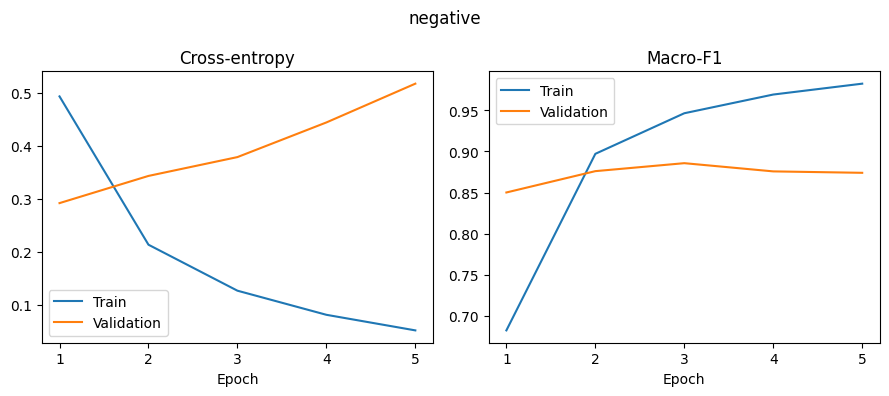

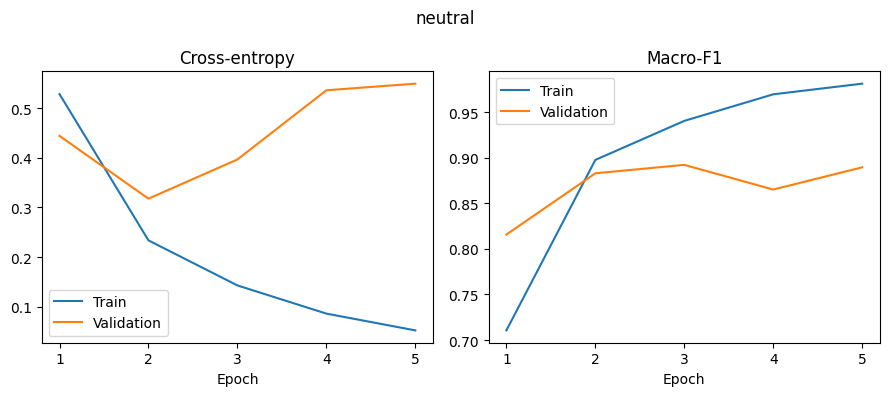

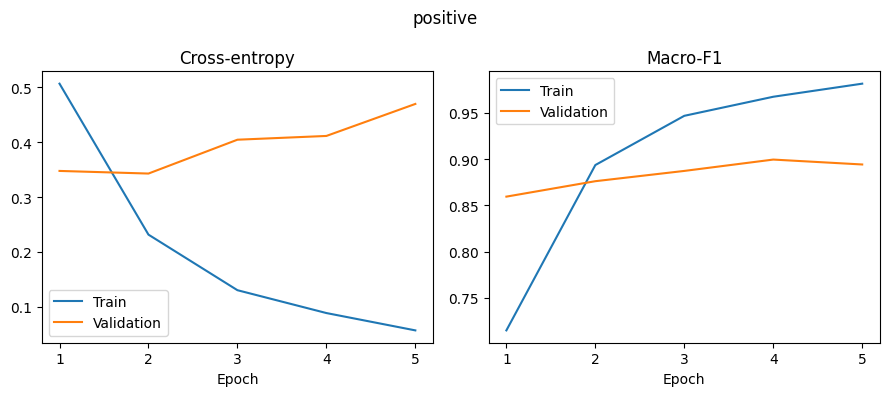

In [4]:
import matplotlib.pyplot as plt

for name, history in histories.items():
    epochs = range(1, len(history) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(9, 4))
    figure.suptitle(name)
    for index, title in enumerate(("Cross-entropy", "Macro-F1")):
        axes[index].plot(epochs, [train[index] for train, _ in history], label="Train")
        axes[index].plot(epochs, [val[index] for _, val in history], label="Validation")
        axes[index].set(xlabel="Epoch", title=title, xticks=list(epochs))
        axes[index].legend()
    figure.tight_layout()
    plt.show()